In [1]:
import numpy as np
import xarray as xr
import rioxarray as rxr
from rioxarray.merge import merge_arrays
import glob
from scipy import interpolate
from pyproj import Proj

In [2]:
"""
Export coordinates for each urban area
KEY: [utm zone, T/F Northern Hemisphere]
"""
proj_zone = {
    'KBWI':[18, True], 'KJFK':[18, True], 'KPHX':[12, True], 'KMIA':[17, True], 'KORD':[16, True], 'KDEN':[13, True],
    'KSEA':[10, True], 'KSFO':[10, True], 'KLAX':[11, True], 'KATL':[16, True], 'CYYZ':[17, True],
    'MMMX':[14, True], 'KLAS':[11, True], 'KSLC':[12, True], 'KDFW':[14, True], 'KIAH':[15, True],
    'KMSY':[15, True], 'KSTL':[15, True], 'KMSP':[15, True], 'KJAX':[17, True], 'KCLT':[17, True],
    'KPHL':[18, True], 'KSAN':[11, True], 'TJSJ':[19, True], 'CYUL':[18, True], 'MGGL':[13, True],
    'MMMY':[14, True], 'MMUN':[16, True], 'KBIL':[12, True], 'MGGT':[15, True], 'MROC':[16, True],
    'MUHA':[17, True], 'MDSD':[19, True], 'MHTG':[16, True], 'MNMG':[16, True], 'MPTO':[17, True],
    'SKBO':[18, True], 'SPJC':[18, False], 'SEQM':[17, True], 'SCEL':[19, False], 'SAEZ':[21, False],
    'SBGR':[23, False], 'SBEG':[20, False], 'SCCI':[19, False],
    'SLLP':[19, False], 'SUMU':[21, False], 'SBBR':[22, False], 'SVMI':[19, True]
}

# Creates a sorted list of the city names
cities = sorted(list(proj_zone.keys()))

In [3]:
# Dictionary for full city name strings
city_str_dict = {
    'KATL': 'Atlanta, Georgia, USA',
    'KBIL': 'Billings, Montana, USA',
    'SKBO': 'Bogota, Colombia',
    'SBBR': 'Brasilia, Brazil',
    'SAEZ': 'Buenos Aires, Argentina',
    'MMUN': 'Cancun, Mexico',
    'SVMI': 'Caracas, Venezuela',
    'KCLT': 'Charlotte, North Carolina, USA',
    'KORD': 'Chicago, Illinois, USA',
    'KDFW': 'Dallas, Texas, USA and Fort Worth, Texas, USA',
    'KDEN': 'Denver, Colorado, USA',
    'MMGL': 'Guadalajara, Mexico',
    'MGGT': 'Guatemala City, Guatemala',
    'MUHA': 'Havana, Cuba',
    'KIAH': 'Houston, Texas, USA',
    'KJAX': 'Jacksonville, Florida, USA',
    'SLLP': 'La Paz, Bolivia',
    'KLAS': 'Las Vegas, Nevada, USA',
    'SPJC': 'Lima, Peru',
    'KLAX': 'Los Angeles, California, USA',
    'MNMG': 'Managua, Nicaragua',
    'SBEG': 'Manaus, Brazil',
    'MMMX': 'Mexico City, Mexico',
    'KMIA': 'Miami, Florida, USA',
    'KMSP': 'Minneapolis, Minnesota, USA',
    'MMMY': 'Monterrey, Mexico',
    'SUMU': 'Montevideo, Uruguay',
    'CYUL': 'Montreal, Quebec, Canada',
    'KMSY': 'New Orleans, Louisiana, USA',
    'KJFK': 'New York City, New York, USA',
    'MPTO': 'Panama City, Panama',
    'KPHL': 'Philadelphia, Pennsylvania, USA',
    'KPHX': 'Phoenix, Arizona, USA',
    'SCCI': 'Punta Arenas, Chile',
    'SEQM': 'Quito, Ecuador',
    'KSLC': 'Salt Lake City, Utah, USA',
    'KSAN': 'San Diego, California, USA and Tijuana, Mexico',
    'KSFO': 'San Francisco, California, USA and San Jose, California, USA',
    'MROC': 'San Jose, Costa Rica',
    'TJSJ': 'San Juan, Puerto Rico',
    'SCEL': 'Santiago, Chile',
    'MDSD': 'Santo Domingo, Dominican Republic',
    'SBGR': 'Sao Paulo, Brazil',
    'KSEA': 'Seattle, Washington, USA',
    'KSTL': 'St Louis, Missouri, USA',
    'MHTG': 'Tegucigalpa, Honduras',
    'CYYZ': 'Toronto, Ontario, Canada',
    'KBWI': 'Washington, DC, USA and Baltimore, Maryland, USA'
}

In [4]:
tmp_dataset_root = '/glade/derecho/scratch/jstarfeldt/uhminicubes_tmp'
DEM_dir = '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/NASADEM_geotiff'
LCZ_dir = '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ'
save_dir = '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/reprocessed_for_gdex/static'

In [5]:
def stacked_to_latlon(pt):
    """
    Reprojects a point in UTM coordinates to
    latitude and longitude coordinates.

    Args:
    pt (tuple-like): Tuple with format (x coord, y coord) to reproject

    Returns:
    (tuple): Tuple with format (longitude, latitude)
    """
    return utm_proj(pt[0], pt[1], inverse=True)

In [4]:
# Process static hresgrid
for city in cities:
    ################################################################
    # Lat/lon Processing
    city_zone = proj_zone[city]
    if city_zone[1]:
        crs_prefix = '326'
    else:
        crs_prefix = '327'
    proj_code = f'EPSG:{crs_prefix}{city_zone[0]}'
    utm_proj = Proj(projparams=proj_code)

    city_dir = f'{tmp_dataset_root}/{city}'
    Landsat_file_list = glob.glob(f'{city_dir}/Landsat/*')

    # Produce Landsat latlons
    ds = rxr.open_rasterio(Landsat_file_list[0])[:, :3000, :3000]
    ds = ds.reindex(y=ds.y[::-1])  # Invert y-axis so that values are increasing instead of decreasing with index
    geotiff_ds = ds.to_dataset('band')
    y, x = np.meshgrid(geotiff_ds['y'], geotiff_ds['x'])
    utm_coords = np.stack((x,y)).T.reshape(-1, 2)

    latlon_pts = np.array(list(map(stacked_to_latlon, utm_coords)))
    latlon_pts = latlon_pts.reshape((3000, 3000, 2))

    ds_hresgrid = geotiff_ds
    ds_hresgrid['latitude'] = (('y', 'x'), latlon_pts[:, :, 1])
    ds_hresgrid['longitude'] = (('y', 'x'), latlon_pts[:, :, 0])
    ds_hresgrid = ds_hresgrid.drop_vars(list(range(1, 14)))

    del ds_hresgrid.attrs['long_name']
    del ds_hresgrid.attrs['scale_factor']
    del ds_hresgrid.attrs['add_offset']
    del ds_hresgrid.attrs['AREA_OR_POINT']
    ds_hresgrid.attrs['title'] = f'Static coordinates and variables of high-resolution grid for {city_str_dict[city]}'
    ds_hresgrid.attrs['institution'] = 'University of Maryland, College Park'

    ds_hresgrid['y'].attrs['standard_name'] = 'projection_y_coordinate'
    ds_hresgrid['y'].attrs['long_name'] = 'UTM Northing'
    ds_hresgrid['y'].attrs['units'] = 'm'

    ds_hresgrid['x'].attrs['standard_name'] = 'projection_x_coordinate'
    ds_hresgrid['x'].attrs['long_name'] = 'UTM Easting'
    ds_hresgrid['x'].attrs['units'] = 'm'

    ds_hresgrid['latitude'].attrs['standard_name'] = 'latitude'
    ds_hresgrid['latitude'].attrs['units'] = 'degree'
    ds_hresgrid['latitude'].attrs['valid_min'] = '-90'
    ds_hresgrid['latitude'].attrs['valid_max'] = '90'

    ds_hresgrid['longitude'].attrs['standard_name'] = 'longitude'
    ds_hresgrid['longitude'].attrs['units'] = 'degree'
    ds_hresgrid['longitude'].attrs['valid_min'] = '-180'
    ds_hresgrid['longitude'].attrs['valid_max'] = '180'

    ################################################################
    # DEM Processing
    DEM_files = sorted(glob.glob(f'{DEM_dir}/{city}/*'))
    ds_DEM = merge_arrays([rxr.open_rasterio(file) for file in DEM_files])

    latlon_pts_hresgrid = np.stack([ds_hresgrid['longitude'], ds_hresgrid['latitude']], axis=-1)
    ds_DEM = ds_DEM.where(ds_DEM != -32768, np.nan)  # Replace the fill value with NaN

    # Add a buffer of 0.1 degrees for interpolation
    buffer = 0.1
    min_lon = np.min(latlon_pts_hresgrid[:, :, 0]) - buffer
    max_lon = np.max(latlon_pts_hresgrid[:, :, 0]) + buffer
    min_lat = np.min(latlon_pts_hresgrid[:, :, 1]) - buffer
    max_lat = np.max(latlon_pts_hresgrid[:, :, 1]) + buffer

    # Mask the combined DEM image to the coordinates of the hresgrid
    mask = (
        (ds_DEM.y >= min_lat) &
        (ds_DEM.y <= max_lat) &
        (ds_DEM.x >= min_lon) &
        (ds_DEM.x <= max_lon))
    ds_DEM = ds_DEM.where(
        mask,
        drop=True)

    # Interpolate the masked DEM image to the coordinates of the hresgrid
    y, x = np.meshgrid(ds_DEM['y'], ds_DEM['x'])
    latlons = np.stack((x, y)).T.reshape(-1, 2)
    DEM_values = ds_DEM[0].values.flatten()
    DEM = interpolate.griddata(latlons, DEM_values, latlon_pts_hresgrid, method='nearest')

    # Set a new variable as the interpolated DEM data
    ds_hresgrid['NASADEM'] = (('y', 'x'), DEM)

    # Add metadata for the DEM variable
    ds_hresgrid['NASADEM'].attrs['standard_name'] = 'height_above_mean_sea_level'
    ds_hresgrid['NASADEM'].attrs['long_name'] = 'NASADEM Merged DEM Global 1 arc second V001'
    ds_hresgrid['NASADEM'].attrs['units'] = 'm'
    ds_hresgrid['NASADEM'].attrs['valid_min'] = -32767
    ds_hresgrid['NASADEM'].attrs['valid_max'] = 32767
    ds_hresgrid['NASADEM'].attrs['_FillValue'] = np.nan

    ################################################################
    # LCZ Processing
    ds_lcz = rxr.open_rasterio(f'{LCZ_dir}/LCZ_{city}.tif')[0]
    ds_lcz = ds_lcz.where(ds_lcz != 0)  # Replace fill value with NaN
    del ds_lcz['band']
    ds_hresgrid['LCZ'] = ds_lcz

    # Add metadata for the LCZ variable
    ds_hresgrid['LCZ'].attrs['standard_name'] = 'area_type'
    ds_hresgrid['LCZ'].attrs['flag_values'] = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
    ds_hresgrid['LCZ'].attrs['flag_meanings'] = "Compact_highrise Compact_midrise Compact_lowrise \
Open_highrise Open_midrise Open_lowrise Lightweight_lowrise Large_lowrise Sparsely_built Heavy_industry \
Dense_trees Scattered_trees Bush_scrub Low_plants Bare_rock_or_paved Bare_soil_or_sand Water"
    ds_hresgrid['LCZ'].attrs['_FillValue'] = np.nan

    ################################################################
    # Save the file
    ds_hresgrid.to_netcdf(f'{save_dir}/hresgrid_{city}_static.nc')

In [5]:
ds_hresgrid

<xarray.Dataset> Size: 288MB
Dimensions:      (x: 3000, y: 3000)
Coordinates:
  * x            (x) float64 24kB 7.322e+05 7.322e+05 ... 8.221e+05 8.221e+05
  * y            (y) float64 24kB 1.982e+06 1.982e+06 ... 2.072e+06 2.072e+06
    spatial_ref  int32 4B ...
Data variables:
    latitude     (y, x) float64 72MB 17.91 17.91 17.91 ... 18.71 18.71 18.71
    longitude    (y, x) float64 72MB -66.81 -66.81 -66.81 ... -65.95 -65.95
    NASADEM      (y, x) float64 72MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    LCZ          (y, x) float64 72MB nan nan nan nan nan ... nan nan nan nan nan
Attributes:
    title:        Latitude and Longitude coordinates of high-resolution grid ...
    institution:  University of Maryland, College Park

In [ ]:
# Process static lresgrid
for city in cities:
    city_zone = proj_zone[city]
    if city_zone[1]:
        crs_prefix = '326'
    else:
        crs_prefix = '327'
    proj_code = f'EPSG:{crs_prefix}{city_zone[0]}'
    utm_proj = Proj(projparams=proj_code)

    city_dir = f'{tmp_dataset_root}/{city}'
    GOES_file_list = glob.glob(f'{city_dir}/GOES_2022_1/*')
    # Produce GOES latlons
    ds = rxr.open_rasterio(GOES_file_list[0])
    ds = ds.reindex(y=ds.y[::-1])  # Invert y-axis so that values are increasing instead of decreasing with index
    geotiff_ds = ds.to_dataset('band')
    y, x = np.meshgrid(ds['y'], ds['x'])
    utm_coords = np.stack((x, y)).T.reshape(-1, 2)

    latlon_pts = np.array(list(map(stacked_to_latlon, utm_coords)))
    latlon_pts = latlon_pts.reshape((45, 45, 2))

    latlon_ds = geotiff_ds
    latlon_ds['latitude'] = (('y', 'x'), latlon_pts[:, :, 1])
    latlon_ds['longitude'] = (('y', 'x'), latlon_pts[:, :, 0])
    latlon_ds = latlon_ds.drop_vars(list(range(1, 5)))

    del latlon_ds.attrs['scale_factor']
    del latlon_ds.attrs['add_offset']
    del latlon_ds.attrs['TIFFTAG_XRESOLUTION']
    del latlon_ds.attrs['TIFFTAG_YRESOLUTION']
    del latlon_ds.attrs['TIFFTAG_RESOLUTIONUNIT']
    del latlon_ds.attrs['_FillValue']
    latlon_ds.attrs['title'] = f'Latitude and Longitude coordinates of low-resolution grid for {city_str_dict[city]}'
    latlon_ds.attrs['institution'] = 'University of Maryland, College Park'

    latlon_ds['y'].attrs['standard_name'] = 'projection_y_coordinate'
    latlon_ds['y'].attrs['long_name'] = 'UTM Northing'
    latlon_ds['y'].attrs['units'] = 'm'

    latlon_ds['x'].attrs['standard_name'] = 'projection_x_coordinate'
    latlon_ds['x'].attrs['long_name'] = 'UTM Easting'
    latlon_ds['x'].attrs['units'] = 'm'

    latlon_ds['latitude'].attrs['standard_name'] = 'latitude'
    latlon_ds['latitude'].attrs['units'] = 'degree'
    latlon_ds['latitude'].attrs['valid_min'] = '-90'
    latlon_ds['latitude'].attrs['valid_max'] = '90'

    latlon_ds['longitude'].attrs['standard_name'] = 'longitude'
    latlon_ds['longitude'].attrs['units'] = 'degree'
    latlon_ds['longitude'].attrs['valid_min'] = '-180'
    latlon_ds['longitude'].attrs['valid_max'] = '180'

    latlon_ds.to_netcdf(f'/glade/derecho/scratch/jstarfeldt/uhminicubes/lresgrid/static/lresgrid_{city}_latlon.nc')

### DEM Example

In [6]:
DEM_files = sorted(glob.glob('/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/NASADEM_geotiff/MMUN/*'))
DEM_files

['/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/NASADEM_geotiff/MMUN/n20w087.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/NASADEM_geotiff/MMUN/n20w088.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/NASADEM_geotiff/MMUN/n21w087.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/NASADEM_geotiff/MMUN/n21w088.tif']

In [7]:
ds_DEM = merge_arrays([rxr.open_rasterio(file) for file in DEM_files])
ds_DEM

<xarray.DataArray (band: 1, y: 7201, x: 7201)> Size: 104MB
array([[[ 0,  0,  0, ...,  0,  0,  0],
        [ 0,  0,  0, ...,  0,  0,  0],
        [ 0,  0,  0, ...,  0,  0,  0],
        ...,
        [22, 18, 18, ...,  0,  0,  0],
        [20, 17, 18, ...,  0,  0,  0],
        [18, 17, 19, ...,  0,  0,  0]]],
      shape=(1, 7201, 7201), dtype=int16)
Coordinates:
  * x            (x) float64 58kB -88.0 -88.0 -88.0 -88.0 ... -86.0 -86.0 -86.0
  * y            (y) float64 58kB 22.0 22.0 22.0 22.0 ... 20.0 20.0 20.0 20.0
  * band         (band) int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     -32768
    scale_factor:   1.0
    add_offset:     0.0

In [8]:
ds_DEM = ds_DEM.where(ds_DEM != -32768, np.nan)
ds_DEM

<xarray.DataArray (band: 1, y: 7201, x: 7201)> Size: 415MB
array([[[ 0.,  0.,  0., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ...,  0.,  0.,  0.],
        ...,
        [22., 18., 18., ...,  0.,  0.,  0.],
        [20., 17., 18., ...,  0.,  0.,  0.],
        [18., 17., 19., ...,  0.,  0.,  0.]]], shape=(1, 7201, 7201))
Coordinates:
  * x            (x) float64 58kB -88.0 -88.0 -88.0 -88.0 ... -86.0 -86.0 -86.0
  * y            (y) float64 58kB 22.0 22.0 22.0 22.0 ... 20.0 20.0 20.0 20.0
  * band         (band) int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     -32768
    scale_factor:   1.0
    add_offset:     0.0

In [9]:
dsL = xr.open_dataset('/gdex/data/d539393/high_resolution/grid/hresgrid_MMUN_latlon.nc')
dsL

<xarray.Dataset> Size: 144MB
Dimensions:      (y: 3000, x: 3000)
Coordinates:
  * x            (x) float64 24kB 4.708e+05 4.708e+05 ... 5.607e+05 5.607e+05
  * y            (y) float64 24kB 2.279e+06 2.279e+06 ... 2.369e+06 2.369e+06
    spatial_ref  int32 4B ...
Data variables:
    latitude     (y, x) float64 72MB ...
    longitude    (y, x) float64 72MB ...
Attributes:
    AREA_OR_POINT:  Area
    title:          Latitude and Longitude coordinates of high-resolution gri...
    institution:    University of Maryland, College Park

In [10]:
latlon_pts_hresgrid = np.stack([dsL['longitude'], dsL['latitude']], axis=-1)
latlon_pts_hresgrid

array([[[-87.28048136,  20.61120691],
        [-87.28019344,  20.61120738],
        [-87.27990552,  20.61120784],
        ...,
        [-86.417596  ,  20.61045338],
        [-86.41730809,  20.61045241],
        [-86.41702019,  20.61045144]],

       [[-87.28048185,  20.61147799],
        [-87.28019394,  20.61147846],
        [-87.27990602,  20.61147892],
        ...,
        [-86.41759497,  20.61072445],
        [-86.41730706,  20.61072348],
        [-86.41701916,  20.61072251]],

       [[-87.28048235,  20.61174907],
        [-87.28019443,  20.61174954],
        [-87.27990651,  20.61175   ],
        ...,
        [-86.41759394,  20.61099552],
        [-86.41730603,  20.61099455],
        [-86.41701813,  20.61099358]],

       ...,

       [[-87.28200457,  21.42359048],
        [-87.28171509,  21.42359097],
        [-87.28142561,  21.42359146],
        ...,
        [-86.41443331,  21.42280445],
        [-86.41414384,  21.42280344],
        [-86.41385437,  21.42280243]],

       [[-87.28

In [11]:
# Add a buffer of 0.1 degrees for interpolation
buffer = 0.1
min_lon = np.min(latlon_pts_hresgrid[:, :, 0]) - buffer
max_lon = np.max(latlon_pts_hresgrid[:, :, 0]) + buffer
min_lat = np.min(latlon_pts_hresgrid[:, :, 1]) - buffer
max_lat = np.max(latlon_pts_hresgrid[:, :, 1]) + buffer

In [12]:
mask = (
    (ds_DEM.y >= min_lat) &
    (ds_DEM.y <= max_lat) &
    (ds_DEM.x >= min_lon) &
    (ds_DEM.x <= max_lon)
)

In [13]:
ds_DEM = ds_DEM.where(
    mask,
    drop=True
)
ds_DEM

<xarray.DataArray (band: 1, y: 3650, x: 3846)> Size: 112MB
array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 3., ..., 0., 0., 0.],
        [1., 2., 3., ..., 0., 0., 0.],
        ...,
        [5., 6., 6., ..., 0., 0., 0.],
        [4., 6., 6., ..., 0., 0., 0.],
        [5., 6., 7., ..., 0., 0., 0.]]], shape=(1, 3650, 3846))
Coordinates:
  * x            (x) float64 31kB -87.38 -87.38 -87.38 ... -86.31 -86.31 -86.31
  * y            (y) float64 29kB 21.52 21.52 21.52 21.52 ... 20.51 20.51 20.51
  * band         (band) int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     -32768
    scale_factor:   1.0
    add_offset:     0.0

In [14]:
DEM_values = ds_DEM[0].values.flatten()
DEM_values

array([0., 0., 0., ..., 0., 0., 0.], shape=(14037900,))

In [15]:
y, x = np.meshgrid(ds_DEM['y'], ds_DEM['x'])
latlons = np.stack((x, y)).T.reshape(-1, 2)
latlons

array([[-87.38194444,  21.52416667],
       [-87.38166667,  21.52416667],
       [-87.38138889,  21.52416667],
       ...,
       [-86.31444444,  20.51055556],
       [-86.31416667,  20.51055556],
       [-86.31388889,  20.51055556]], shape=(14037900, 2))

In [16]:
DEM = interpolate.griddata(latlons, DEM_values, latlon_pts_hresgrid, method='nearest')
DEM

array([[19., 19., 19., ...,  0.,  0.,  0.],
       [18., 17., 17., ...,  0.,  0.,  0.],
       [20., 18., 18., ...,  0.,  0.,  0.],
       ...,
       [ 4.,  5.,  6., ...,  0.,  0.,  0.],
       [ 5.,  6.,  7., ...,  0.,  0.,  0.],
       [ 6.,  7.,  8., ...,  0.,  0.,  0.]], shape=(3000, 3000))

In [17]:
np.sum(np.isnan(DEM))

np.int64(0)

In [18]:
dsL['NASADEM'] = (('y', 'x'), DEM)
dsL

<xarray.Dataset> Size: 216MB
Dimensions:      (y: 3000, x: 3000)
Coordinates:
  * x            (x) float64 24kB 4.708e+05 4.708e+05 ... 5.607e+05 5.607e+05
  * y            (y) float64 24kB 2.279e+06 2.279e+06 ... 2.369e+06 2.369e+06
    spatial_ref  int32 4B ...
Data variables:
    latitude     (y, x) float64 72MB 20.61 20.61 20.61 ... 21.42 21.42 21.42
    longitude    (y, x) float64 72MB -87.28 -87.28 -87.28 ... -86.41 -86.41
    NASADEM      (y, x) float64 72MB 19.0 19.0 19.0 18.0 ... 0.0 0.0 0.0 0.0
Attributes:
    AREA_OR_POINT:  Area
    title:          Latitude and Longitude coordinates of high-resolution gri...
    institution:    University of Maryland, College Park

In [19]:
dsL['NASADEM'].attrs['standard_name'] = 'height_above_mean_sea_level'
dsL['NASADEM'].attrs['long_name'] = 'NASADEM Merged DEM Global 1 arc second V001'
dsL['NASADEM'].attrs['units'] = 'm'
dsL['NASADEM'].attrs['valid_min'] = -32767
dsL['NASADEM'].attrs['valid_max'] = 32767
dsL['NASADEM'].attrs['_FillValue'] = np.nan

In [20]:
import matplotlib.pyplot as plt

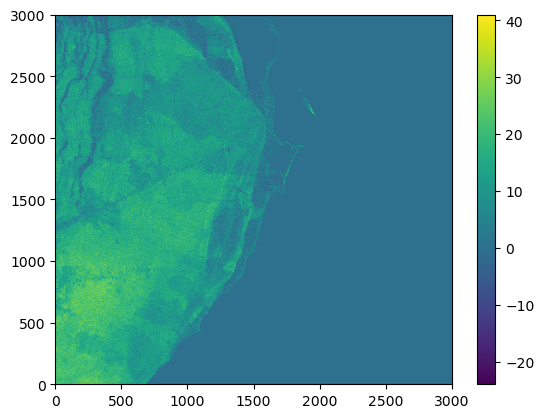

In [21]:
cb = plt.pcolormesh(DEM)
plt.colorbar(cb)

### LCZ Example

In [22]:
LCZ_files = sorted(glob.glob(LCZ_dir+'/*'))
LCZ_files

['/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_CYUL.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_CYYZ.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KATL.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KBIL.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KBWI.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KCLT.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KDEN.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KDFW.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KIAH.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KJAX.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KJFK.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KLAS.tif',
 '/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/LCZ/LCZ_KLAX.tif',
 '/glade/der

In [23]:
ds_lcz = rxr.open_rasterio(f'{LCZ_dir}/LCZ_MMUN.tif')[0]
ds_lcz = ds_lcz.where(ds_lcz != 0)
del ds_lcz['band']
ds_lcz

<xarray.DataArray (y: 3001, x: 3000)> Size: 72MB
array([[11., 11., 11., ..., nan, nan, nan],
       [11., 11., 11., ..., nan, nan, nan],
       [11., 11., 11., ..., nan, nan, nan],
       ...,
       [11., 11., 11., ..., nan, nan, nan],
       [11., 11., 11., ..., nan, nan, nan],
       [11., 11., 11., ..., nan, nan, nan]], shape=(3001, 3000))
Coordinates:
  * x            (x) float64 24kB 4.708e+05 4.708e+05 ... 5.607e+05 5.607e+05
  * y            (y) float64 24kB 2.369e+06 2.369e+06 ... 2.279e+06 2.279e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      LCZ_Filter

In [24]:
dsL['LCZ'] = ds_lcz
dsL

<xarray.Dataset> Size: 288MB
Dimensions:      (x: 3000, y: 3000)
Coordinates:
  * x            (x) float64 24kB 4.708e+05 4.708e+05 ... 5.607e+05 5.607e+05
  * y            (y) float64 24kB 2.279e+06 2.279e+06 ... 2.369e+06 2.369e+06
    spatial_ref  int32 4B ...
Data variables:
    latitude     (y, x) float64 72MB 20.61 20.61 20.61 ... 21.42 21.42 21.42
    longitude    (y, x) float64 72MB -87.28 -87.28 -87.28 ... -86.41 -86.41
    NASADEM      (y, x) float64 72MB 19.0 19.0 19.0 18.0 ... 0.0 0.0 0.0 0.0
    LCZ          (y, x) float64 72MB 11.0 11.0 11.0 11.0 ... nan nan nan nan
Attributes:
    AREA_OR_POINT:  Area
    title:          Latitude and Longitude coordinates of high-resolution gri...
    institution:    University of Maryland, College Park

In [25]:
dsL['LCZ'].attrs['standard_name'] = 'area_type'
dsL['LCZ'].attrs['flag_values'] = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
dsL['LCZ'].attrs['flag_meanings'] = "Compact_highrise Compact_midrise Compact_lowrise \
Open_highrise Open_midrise Open_lowrise Lightweight_lowrise Large_lowrise Sparsely_built Heavy_industry \
Dense_trees Scattered_trees Bush_scrub Low_plants Bare_rock_or_paved Bare_soil_or_sand Water"
dsL['LCZ'].attrs['_FillValue'] = np.nan

In [26]:
dsL

<xarray.Dataset> Size: 288MB
Dimensions:      (x: 3000, y: 3000)
Coordinates:
  * x            (x) float64 24kB 4.708e+05 4.708e+05 ... 5.607e+05 5.607e+05
  * y            (y) float64 24kB 2.279e+06 2.279e+06 ... 2.369e+06 2.369e+06
    spatial_ref  int32 4B ...
Data variables:
    latitude     (y, x) float64 72MB 20.61 20.61 20.61 ... 21.42 21.42 21.42
    longitude    (y, x) float64 72MB -87.28 -87.28 -87.28 ... -86.41 -86.41
    NASADEM      (y, x) float64 72MB 19.0 19.0 19.0 18.0 ... 0.0 0.0 0.0 0.0
    LCZ          (y, x) float64 72MB 11.0 11.0 11.0 11.0 ... nan nan nan nan
Attributes:
    AREA_OR_POINT:  Area
    title:          Latitude and Longitude coordinates of high-resolution gri...
    institution:    University of Maryland, College Park